# Q-Control-Optimization: выбор резервных линий подстанции на квантовом компьютере

Ноутбук собран из файлов проекта: каждая ячейка с кодом - это файл из `src/` один в один.
**Выполняйте ячейки сверху вниз** (Shift+Enter). Результаты появятся в папке `results/` рядом с ноутбуком.

| Ячейка | Что делает | Время |
|---|---|---|
| Ключ API | читает ключ из `key.txt` в память ядра (нужен только шагу 4) | - |
| Настройки | записывает `data/config.json` | мгновенно |
| Общие функции | определяет функции для всех шагов, ничего не печатает | мгновенно |
| Шаг 1 | задача, энергии всех 16 вариантов, оптимум перебором | < 1 с |
| Шаг 2 | квантовые схемы, подбор углов, теория | несколько секунд |
| Шаг 3 | симулятор CPUQVM (без интернета) - по желанию | < 1 с |
| Шаг 4 | отправка на квантовый компьютер Wukong 180-2 и сбор результата | секунды за запуск |
| Шаг 5 | сравнение теории, симулятора и QPU, график | ~1 с |

## Ключ API
Создайте рядом с ноутбуком файл `key.txt` (File -> New -> Text File) и вставьте в него только ключ
из консоли OriginQC - одной строкой, без кавычек и `api_key =`. Ключ в ноутбук не попадает и не печатается.

In [3]:
# ===== Ключ API =====
# Ключ лежит в файле key.txt рядом с ноутбуком (или в src/key.txt): одна строка, только сам ключ.
# Создать файл в JupyterLab: File -> New -> Text File, вставить ключ, сохранить как key.txt.
# Ячейка кладёт ключ в память ядра для шага 4. Сам ключ не печатается.
import os
os.environ.pop("ORIGINQC_API_KEY", None)          # забыть ключ, введённый раньше через поле
for path in ("key.txt", os.path.join("src", "key.txt")):
    if os.path.exists(path):
        with open(path, encoding="utf-8") as f:
            lines = [l.strip().strip('"').strip("'").strip() for l in f.read().replace("\ufeff", "").splitlines()]
        key = next((l for l in lines if l), "")
        os.environ["ORIGINQC_API_KEY"] = key
        warn = " - ВНИМАНИЕ: внутри ключа пробел или '='" if any(c.isspace() or c == "=" for c in key) else ""
        print(f"Ключ взят из {path}: длина {len(key)} символов{warn}")
        break
else:
    print("Нет файла key.txt рядом с ноутбуком - создайте его (см. комментарий выше)")

Ключ взят из key.txt: длина 128 символов


## Настройки
Задача (потери линий, ограничения, штрафы) и параметры запуска. Главное для запуска:
`shots` - число повторов каждой схемы, `qpu_backend` - квантовый компьютер, `qpu_circuits` - какие схемы
отправить на него, `cloud_simulator` - облачный симулятор (выключен: `null`).

In [4]:
# ===== data/config.json - параметры задачи и запуска =====
# Эта ячейка записывает файл data/config.json рядом с ноутбуком. Менять параметры можно прямо здесь.
import json, os
CONFIG = json.loads("""
{
  "n_vars": 4,
  "objective_costs": [1.2, 0.8, 1.5, 0.9],
  "equality_constraints": [
    {"indices": [0, 1, 2, 3], "target_sum": 2, "penalty": 50.0}
  ],
  "inequality_constraints": [
    {"indices": [0, 3], "penalty": 100.0, "type": "mutual_exclusion"}
  ],
  "experiment": {
    "shots": 1000,
    "xy_conflict_penalty": 1.0,
    "legacy_angles": {"gamma": 0.5, "beta": 0.3},
    "cloud_simulator": null,
    "qpu_backend": "WK_C180_2",
    "qpu_circuits": ["calib", "penalty_qaoa", "xy_qaoa"],
    "qpu_amend": true,
    "time_budget_sec": 35
  }
}
""")
os.makedirs("data", exist_ok=True)
with open("data/config.json", "w", encoding="utf-8") as f:
    json.dump(CONFIG, f, indent=2, ensure_ascii=False)
print("Записан data/config.json:", json.dumps(CONFIG["experiment"], ensure_ascii=False))

Записан data/config.json: {"shots": 1000, "xy_conflict_penalty": 1.0, "legacy_angles": {"gamma": 0.5, "beta": 0.3}, "cloud_simulator": null, "qpu_backend": "WK_C180_2", "qpu_circuits": ["calib", "penalty_qaoa", "xy_qaoa"], "qpu_amend": true, "time_budget_sec": 35}


## Общие функции (src/common.py)
Построение QUBO, гейты и схемы, точный симулятор, подбор углов, метрики, разбор ответов бэкенда.
Ячейка только определяет функции - вывода нет. Её нужно выполнить до шагов.

In [5]:
# ===== src/common.py (код файла проекта 1:1) =====
# -*- coding: utf-8 -*-
"""
common.py - общие функции, которыми пользуются все шаги проекта.

Разделы:
  1. Пути и файлы JSON
  2. Задача: QUBO, энергии, допустимость (шаг 1)
  3. Гейты и схемы - только H, X, RX, RZ, CNOT (шаг 2)
  4. Точный симулятор на numpy и подбор углов (шаг 2)
  5. Метрики качества (шаги 3-5)
  6. Ключи результатов и порядок битов (шаги 3-5)
  7. Перевод схемы в программу pyqpanda3 (шаги 3-4)

Соглашение об индексах: состояние x = (x0, x1, x2, x3), x_i = 1 - линия i включена.
В массивах вероятностей индекс k = int("x0x1x2x3", 2), то есть x0 - старший бит.
"""
import json
import math
import os
from itertools import product

import numpy as np

PI = math.pi

# ============================================================================ 1. Пути и файлы JSON
# Файлом (python, %run) - папка проекта над src/; кодом в ячейке ноутбука - текущая папка ноутбука.
SRC_DIR = os.path.dirname(os.path.abspath(globals().get("__file__", os.path.join(os.getcwd(), "src", "common.py"))))
ROOT = os.path.dirname(SRC_DIR)
CONFIG_PATH = os.path.join(ROOT, "data", "config.json")
RESULTS_DIR = os.path.join(ROOT, "results")
STEP1_PATH = os.path.join(RESULTS_DIR, "step1_problem.json")
STEP2_PATH = os.path.join(RESULTS_DIR, "step2_circuits.json")
STEP3_PATH = os.path.join(RESULTS_DIR, "step3_local.json")
STEP4_PATH = os.path.join(RESULTS_DIR, "step4_cloud.json")
STEP5_REPORT = os.path.join(RESULTS_DIR, "step5_report.md")
STEP5_PLOT = os.path.join(RESULTS_DIR, "step5_plot.png")


def to_jsonable(obj):
    if isinstance(obj, dict):
        return {str(k): to_jsonable(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [to_jsonable(v) for v in obj]
    if isinstance(obj, np.ndarray):
        return [to_jsonable(v) for v in obj.tolist()]
    if isinstance(obj, (np.floating, np.integer, np.bool_)):
        return obj.item()
    if isinstance(obj, (bool, int, float, str)) or obj is None:
        return obj
    return str(obj)


def save_json(path, obj):
    os.makedirs(os.path.dirname(path), exist_ok=True)
    tmp = path + ".tmp"
    with open(tmp, "w", encoding="utf-8") as f:
        json.dump(to_jsonable(obj), f, indent=1, ensure_ascii=False)
    os.replace(tmp, path)          # файл никогда не остаётся записанным наполовину


def load_json(path, hint):
    if not os.path.exists(path):
        raise SystemExit(f"Нет файла {os.path.relpath(path, ROOT)} - сначала выполните {hint}.")
    with open(path, encoding="utf-8") as f:
        return json.load(f)


def load_config():
    with open(CONFIG_PATH, encoding="utf-8") as f:
        return json.load(f)


def pyqpanda3_version():
    try:
        from importlib.metadata import version
        return version("pyqpanda3")
    except Exception:  # noqa: BLE001
        return "не установлен"


def rel(path):
    return os.path.relpath(path, ROOT)


# ============================================================================ 2. Задача
def build_qubo(cfg):
    """H(x) = x^T Q x + offset: потери + штрафы за нарушение ограничений (как в старом qubo_builder.py)."""
    n = cfg["n_vars"]
    Q = np.zeros((n, n))
    offset = 0.0
    for i in range(n):
        Q[i, i] += cfg["objective_costs"][i]
    for ec in cfg.get("equality_constraints", []):           # P * (sum x_i - t)^2
        P, idx, t = ec["penalty"], ec["indices"], ec["target_sum"]
        for i in idx:
            Q[i, i] += P * (1 - 2 * t)                       # x_i^2 = x_i
            for j in idx:
                if j > i:
                    Q[i, j] += P
                    Q[j, i] += P
        offset += P * t ** 2
    for ic in cfg.get("inequality_constraints", []):         # P * x_i * x_j
        P = ic["penalty"]
        i, j = ic["indices"]
        Q[i, j] += P / 2
        Q[j, i] += P / 2
    return Q, offset


def violations(x, cfg):
    """Список нарушенных ограничений (пустой - решение допустимо)."""
    out = []
    for ec in cfg.get("equality_constraints", []):
        s = sum(x[i] for i in ec["indices"])
        if s != ec["target_sum"]:
            out.append(f"включено линий: {s} (нужно {ec['target_sum']})")
    for ic in cfg.get("inequality_constraints", []):
        i, j = ic["indices"]
        if x[i] and x[j]:
            out.append(f"КЗ: линии {i} и {j} вместе")
    return out


def qubo_to_ising(Q):
    """x_i = (1 - Z_i)/2  ->  H = const + sum h_i Z_i + sum_{i<j} J_ij Z_i Z_j."""
    n = len(Q)
    h = np.zeros(n)
    J = np.zeros((n, n))
    for i in range(n):
        h[i] = -Q[i, i] / 2.0
        for j in range(n):
            if i != j:
                h[i] -= (Q[i, j] + Q[j, i]) / 4.0
    for i in range(n):
        for j in range(i + 1, n):
            J[i, j] = (Q[i, j] + Q[j, i]) / 4.0
    return h, J


def energies(Q, offset, states):
    return np.array([float(np.array(x) @ Q @ np.array(x) + offset) for x in states])


def xstr(k, n):
    return format(k, f"0{n}b")      # строка x0 x1 ... x_{n-1}


class Problem:
    """Всё о задаче: 16 состояний, их энергии, допустимость, классический оптимум (полный перебор)."""

    def __init__(self, cfg):
        self.cfg = cfg
        self.n = cfg["n_vars"]
        self.Q, self.offset = build_qubo(cfg)
        self.states = list(product((0, 1), repeat=self.n))
        self.E = energies(self.Q, self.offset, self.states)
        self.feasible = np.array([not violations(x, cfg) for x in self.states])
        self.E_opt = float(self.E[self.feasible].min())
        self.optimal = self.feasible & np.isclose(self.E, self.E_opt)

    def opt_strings(self):
        return [xstr(k, self.n) for k in np.where(self.optimal)[0]]


RUN_KEYS = ("shots", "cloud_simulator", "qpu_backend", "qpu_circuits", "qpu_amend", "time_budget_sec")


def run_settings(s2):
    """Настройки запуска (шоты, бэкенды, лимит времени) - из текущего config.json, их можно менять после шага 2.
    Задача и параметры схем должны совпадать с теми, по которым строились схемы на шаге 2."""
    now = load_config()

    def core(cfg):
        c = {k: v for k, v in cfg.items() if k != "experiment"}
        c["circuit_params"] = {k: v for k, v in cfg.get("experiment", {}).items() if k not in RUN_KEYS}
        return c
    if core(now) != core(s2["config"]):
        raise SystemExit("data/config.json: задача или параметры схем изменились после шага 2 - "
                         "перезапустите шаги 1 и 2.")
    return now["experiment"]


def load_circuits():
    """Результат шага 2: (данные шага, Problem, {схема: гейты}, {схема: теоретические вероятности})."""
    s2 = load_json(STEP2_PATH, "шаги 1-2 (src/step1_problem.py, src/step2_circuits.py)")
    P = Problem(s2["config"])
    gates = {k: v["gates"] for k, v in s2["circuits"].items()}
    exact = {k: np.array([v["exact"][xstr(i, P.n)] for i in range(2 ** P.n)]) for k, v in s2["circuits"].items()}
    return s2, P, gates, exact


# ============================================================================ 3. Гейты и схемы
# Схема - список кортежей: ("H", q), ("X", q), ("RX", q, угол), ("RZ", q, угол), ("CNOT", управляющий, целевой).
def g_ry(q, theta):                  # RY(theta) = RZ(pi/2) RX(theta) RZ(-pi/2)
    return [("RZ", q, -PI / 2), ("RX", q, theta), ("RZ", q, PI / 2)]


def g_cry(c, t, theta):              # управляемый RY: 2 CNOT
    return g_ry(t, theta / 2) + [("CNOT", c, t)] + g_ry(t, -theta / 2) + [("CNOT", c, t)]


def g_xy(a, b, theta):               # exp(-i theta/2 (XX + YY)): обмен |01> <-> |10>, 2 CNOT
    return [("RX", a, PI / 2), ("RX", b, PI / 2), ("CNOT", a, b), ("RX", a, theta), ("RZ", b, theta),
            ("CNOT", a, b), ("RX", a, -PI / 2), ("RX", b, -PI / 2)]


def g_givens(i, j, theta):           # вещественный поворот |1_i 0_j> -> cos|10> + sin|01>, 2 CNOT
    return [("RZ", i, PI / 2)] + g_xy(i, j, theta) + [("RZ", i, -PI / 2)]


def prep_plus(n):
    """|+>^n - равная суперпозиция всех 16 вариантов."""
    return [("H", q) for q in range(n)]


def prep_dicke_4_2():
    """Состояние Дикке D(4,2) - равная суперпозиция 6 вариантов, где включены ровно 2 линии. 8 CNOT.
    1) вес пары A=(0,1) кодируется унарно: 0 -> 00 (1/6), 1 -> 10 (4/6), 2 -> 11 (1/6);
       пара B=(2,3) получает дополнение до 2 (CNOT + X);
    2) внутри каждой пары |10> превращается в (|10> + |01>)/sqrt(2)."""
    t0 = 2 * math.acos(1 / math.sqrt(6))
    t1 = 2 * math.acos(2 / math.sqrt(5))
    return (g_ry(0, t0) + g_cry(0, 1, t1)
            + [("CNOT", 1, 2), ("X", 2), ("CNOT", 0, 3), ("X", 3)]
            + g_givens(0, 1, PI / 4) + g_givens(2, 3, PI / 4))


def cost_layer(h, J, gamma, scale):
    """exp(-i gamma H / scale): RZ на каждом кубите и CNOT-RZ-CNOT на каждой паре."""
    n = len(h)
    gates = []
    for q in range(n):
        if abs(h[q]) > 1e-12:
            gates.append(("RZ", q, 2.0 * gamma * h[q] / scale))
    for i in range(n):
        for j in range(i + 1, n):
            if abs(J[i, j]) > 1e-12:
                gates += [("CNOT", i, j), ("RZ", j, 2.0 * gamma * J[i, j] / scale), ("CNOT", i, j)]
    return gates


def mixer_x(n, beta):
    """Обычный смеситель exp(-i beta sum X): может менять число включённых линий."""
    return [("RX", q, 2.0 * beta) for q in range(n)]


def mixer_xy_ring(beta):
    """XY-смеситель по кольцу 0-1-2-3-0: только переносит "включённость" между соседями,
    число включённых линий не меняется."""
    return g_xy(0, 1, beta) + g_xy(2, 3, beta) + g_xy(1, 2, beta) + g_xy(3, 0, beta)


def gate_counts(gates):
    two = sum(1 for g in gates if g[0] == "CNOT")
    return len(gates) - two, two


def xy_supported(cfg):
    """XY-схема написана для 4 линий с ограничением "включено ровно 2"."""
    ecs = cfg.get("equality_constraints", [])
    return (cfg["n_vars"] == 4 and len(ecs) == 1 and sorted(ecs[0]["indices"]) == [0, 1, 2, 3]
            and ecs[0]["target_sum"] == 2)


# ============================================================================ 4. Точный симулятор и подбор углов
_H = np.array([[1, 1], [1, -1]], dtype=complex) / math.sqrt(2)
_X = np.array([[0, 1], [1, 0]], dtype=complex)


def _rx(theta):                      # как в pyqpanda3: RX(theta) = exp(-i theta X / 2)
    c, s = math.cos(theta / 2), math.sin(theta / 2)
    return np.array([[c, -1j * s], [-1j * s, c]])


def _rz(theta):                      # как в pyqpanda3: RZ(theta) = diag(e^{-i theta/2}, e^{i theta/2})
    return np.diag([np.exp(-0.5j * theta), np.exp(0.5j * theta)])


def simulate_state(gates, n, psi=None):
    """Вектор состояния после схемы (точно, без шума и без выборки)."""
    if psi is None:
        psi = np.zeros(2 ** n, dtype=complex)
        psi[0] = 1.0
    psi = np.asarray(psi, dtype=complex).reshape((2,) * n).copy()
    for g in gates:
        if g[0] == "CNOT":
            c, t = g[1], g[2]
            idx = [slice(None)] * n
            idx[c] = 1
            idx = tuple(idx)
            psi[idx] = np.flip(psi[idx].copy(), axis=t if t < c else t - 1)
            continue
        U = {"H": _H, "X": _X}.get(g[0])
        if U is None:
            U = _rx(g[2]) if g[0] == "RX" else _rz(g[2])
        psi = np.moveaxis(np.tensordot(U, psi, axes=([1], [g[1]])), 0, g[1])
    return psi.reshape(-1)


def simulate_probs(gates, n):
    return np.abs(simulate_state(gates, n)) ** 2


def unitary_of(gates, n):
    eye = np.eye(2 ** n, dtype=complex)
    return np.array([simulate_state(gates, n, eye[k]) for k in range(2 ** n)]).T


def optimize_p1(psi0, E_cost, scale, mixer_fn, n, g_max, b_max, ng=801, nb=181):
    """Подбор (gamma, beta) для p=1: минимум средней энергии <E_cost>.
    Состояние: |psi> = M(beta) exp(-i gamma E_cost/scale) |psi0>. Сетка, затем уточнение вокруг лучшей точки."""
    Es = E_cost / scale

    def search(gammas, betas):
        phase = np.exp(-1j * np.outer(Es, gammas)) * psi0[:, None]
        best = (math.inf, 0.0, 0.0)
        for beta in betas:
            expv = E_cost @ (np.abs(unitary_of(mixer_fn(beta), n) @ phase) ** 2)
            k = int(np.argmin(expv))
            if expv[k] < best[0]:
                best = (float(expv[k]), float(gammas[k]), float(beta))
        return best

    gg = np.linspace(-g_max, g_max, ng)
    bb = np.linspace(-b_max, b_max, nb)
    _, g0, b0 = search(gg, bb)
    dg, db = gg[1] - gg[0], bb[1] - bb[0]
    _, g1, b1 = search(np.linspace(g0 - 2 * dg, g0 + 2 * dg, 101), np.linspace(b0 - 2 * db, b0 + 2 * db, 101))
    return g1, b1


# ============================================================================ 5. Метрики
def metrics(problem, p, exact=None):
    """P(opt) - доля оптимума; P(feas) - доля допустимых; P(opt|feas) - доля оптимума среди допустимых;
    <H> - средняя энергия; mode - самое частое состояние; TVD - расстояние до теории (0 - совпадение, 1 - ничего общего)."""
    p = np.asarray(p, dtype=float)
    p = p / p.sum()
    feas_sorted = [k for k in np.argsort(-p, kind="stable") if problem.feasible[k]]
    ranks = [r + 1 for r, k in enumerate(feas_sorted) if problem.optimal[k]]
    p_feas = float(p[problem.feasible].sum())
    m = {
        "p_opt": float(p[problem.optimal].sum()),
        "p_feasible": p_feas,
        "p_opt_given_feasible": float(p[problem.optimal].sum() / p_feas) if p_feas > 0 else None,
        "exp_H": float(p @ problem.E),
        "mode": xstr(int(np.argmax(p)), problem.n),
        "opt_rank_among_feasible": ranks[0] if ranks else None,
    }
    if exact is not None:
        m["tvd"] = float(0.5 * np.abs(p - np.asarray(exact)).sum())
    return m


# ============================================================================ 6. Ключи результатов и порядок битов
def key_to_bits(key, n):
    """'0101' или '0x5' -> строка из n символов в том порядке, как её выдал бэкенд."""
    k = str(key).strip().replace(" ", "")
    if k.lower().startswith("0x"):
        v = int(k, 16)
        if v >= 2 ** n:
            raise ValueError(f"ключ {key!r} не помещается в {n} бит")
        return format(v, f"0{n}b")
    if k and set(k) <= {"0", "1"} and len(k) <= n:
        return k.zfill(n)
    raise ValueError(f"неожиданный ключ результата {key!r}")


def detect_order(raw_calib, n):
    """Калибровка: схема X(q0) должна дать одну единицу. Где она стоит - там в ключе кубит 0."""
    agg = {}
    for key, val in raw_calib.items():
        b = key_to_bits(key, n)
        agg[b] = agg.get(b, 0.0) + float(val)
    total = sum(agg.values())
    top = max(agg, key=agg.get)
    if top.count("1") != 1 or top.index("1") not in (0, n - 1):
        raise RuntimeError(f"калибровка X(q0) дала неожиданный ключ {top!r}: {agg}")
    return ("q0_left" if top.index("1") == 0 else "q0_right"), top, agg[top] / total


def raw_to_probs(raw, n, order):
    """{ключ: счёт или вероятность} -> массив вероятностей в нашем порядке (x0 - старший бит)."""
    arr = np.zeros(2 ** n)
    for key, val in raw.items():
        b = key_to_bits(key, n)
        if order == "q0_right":
            b = b[::-1]
        arr[int(b, 2)] += max(float(val), 0.0)
    if arr.sum() <= 0:
        raise ValueError("пустое распределение")
    return arr / arr.sum()


def analyse_raw(problem, exact, raws):
    """Сырые результаты одного бэкенда -> порядок битов + вероятности и метрики по каждой схеме."""
    order, top, share = detect_order(raws["calib"], problem.n)
    out = {"order": order, "calib_top": top, "calib_share": share, "probs": {}, "metrics": {}}
    for name, raw in raws.items():
        if name == "calib" or name not in exact:
            continue
        p = raw_to_probs(raw, problem.n, order)
        out["probs"][name] = p
        out["metrics"][name] = metrics(problem, p, exact[name])
    return out


# ============================================================================ 7. pyqpanda3
def to_qprog(gates, n):
    """Наша схема -> QProg. В конце каждый кубит q измеряется в классический бит q."""
    from pyqpanda3.core import QProg, H, X, RX, RZ, CNOT, measure
    prog = QProg()
    for g in gates:
        op = g[0]
        if op == "H":
            prog << H(g[1])
        elif op == "X":
            prog << X(g[1])
        elif op == "RX":
            prog << RX(g[1], float(g[2]))
        elif op == "RZ":
            prog << RZ(g[1], float(g[2]))
        elif op == "CNOT":
            prog << CNOT(g[1], g[2])
        else:
            raise ValueError(f"неизвестный гейт {op}")
    for q in range(n):
        prog << measure(q, q)
    return prog

## Шаг 1. Постановка задачи
Печатает матрицу QUBO, энергию всех 16 вариантов включения линий с оценкой (оптимум / допустимо / какое
ограничение нарушено) и классический оптимум. Создаёт `results/step1_problem.json`.

In [6]:
# ===== src/step1_problem.py (код файла проекта 1:1) =====
# -*- coding: utf-8 -*-
"""
Шаг 1. Постановка задачи.

Что делает: читает data/config.json, строит QUBO (потери + штрафы), считает энергию всех 16 вариантов
включения линий и находит классический оптимум полным перебором. Это эталон, с которым сравнивается
квантовая часть.

Вход:  data/config.json
Выход: results/step1_problem.json
Запуск: python src/step1_problem.py      (в Jupyter: %run src/step1_problem.py)
"""
import importlib
import os
import sys
import time

# Общие функции: если код common.py вставлен в ячейку ноутбука выше - берём их оттуда,
# иначе импортируем файл src/common.py (запуск через python или %run).
if "load_circuits" in globals() and "Problem" in globals():
    import types
    C = types.SimpleNamespace(**globals())
else:
    sys.path.insert(0, os.path.dirname(os.path.abspath(
        globals().get("__file__", os.path.join(os.getcwd(), "src", "_")))))
    try:
        import common as C  # noqa: E402
    except ImportError:
        raise SystemExit("Нет общих функций: сначала выполните ячейку с кодом src/common.py "
                         "(или положите файл src/common.py рядом).")
    C = importlib.reload(C)   # Jupyter кеширует модули: перечитываем, если common.py обновили


def main():
    t0 = time.time()
    cfg = C.load_config()
    P = C.Problem(cfg)
    n = P.n
    print("=" * 72)
    print("ШАГ 1. Постановка задачи: QUBO и классический оптимум")
    print("=" * 72)
    print(f"Линий: {n}; потери при включении линии i: {cfg['objective_costs']}")
    for ec in cfg["equality_constraints"]:
        print(f"Ограничение-равенство: включено ровно {ec['target_sum']} из линий {ec['indices']} "
              f"(штраф {ec['penalty']} x (сумма - {ec['target_sum']})^2)")
    for ic in cfg["inequality_constraints"]:
        print(f"Запрет: линии {ic['indices'][0]} и {ic['indices'][1]} вместе - короткое замыкание "
              f"(штраф {ic['penalty']})")
    print(f"\nH(x) = x^T Q x + {P.offset:g},  Q =")
    for row in P.Q:
        print("   " + "  ".join(f"{v:8.1f}" for v in row))

    print("\nВсе 16 вариантов, по возрастанию энергии (x = x0 x1 x2 x3, 1 - линия включена):")
    print(f"   {'x':<6}{'H(x)':>9}   оценка")
    for k in sorted(range(2 ** n), key=lambda k: P.E[k]):
        x = P.states[k]
        v = C.violations(x, cfg)
        mark = "ОПТИМУМ" if P.optimal[k] else ("допустимо" if not v else "; ".join(v))
        print(f"   {C.xstr(k, n):<6}{P.E[k]:9.3f}   {mark}")

    opt = P.opt_strings()
    on = [i for i, b in enumerate(opt[0]) if b == "1"]
    print(f"\nКлассический оптимум (полный перебор {2 ** n} вариантов): {opt}, H = {P.E_opt:.3f} "
          f"- включить линии {on}")
    print(f"Допустимых вариантов: {int(P.feasible.sum())} из {2 ** n}")

    C.save_json(C.STEP1_PATH, {
        "config": cfg,
        "Q": P.Q, "offset": P.offset,
        "energies": {C.xstr(k, n): float(P.E[k]) for k in range(2 ** n)},
        "feasible": [C.xstr(k, n) for k in range(2 ** n) if P.feasible[k]],
        "optimum": opt, "E_opt": P.E_opt,
    })
    print(f"\nСохранено: {C.rel(C.STEP1_PATH)}   ({time.time() - t0:.1f} с)")


if __name__ == "__main__":
    main()

ШАГ 1. Постановка задачи: QUBO и классический оптимум
Линий: 4; потери при включении линии i: [1.2, 0.8, 1.5, 0.9]
Ограничение-равенство: включено ровно 2 из линий [0, 1, 2, 3] (штраф 50.0 x (сумма - 2)^2)
Запрет: линии 0 и 3 вместе - короткое замыкание (штраф 100.0)

H(x) = x^T Q x + 200,  Q =
     -148.8      50.0      50.0     100.0
       50.0    -149.2      50.0      50.0
       50.0      50.0    -148.5      50.0
      100.0      50.0      50.0    -149.1

Все 16 вариантов, по возрастанию энергии (x = x0 x1 x2 x3, 1 - линия включена):
   x          H(x)   оценка
   0101      1.700   ОПТИМУМ
   1100      2.000   допустимо
   0110      2.300   допустимо
   0011      2.400   допустимо
   1010      2.700   допустимо
   0100     50.800   включено линий: 1 (нужно 2)
   0001     50.900   включено линий: 1 (нужно 2)
   1000     51.200   включено линий: 1 (нужно 2)
   0010     51.500   включено линий: 1 (нужно 2)
   0111     53.200   включено линий: 3 (нужно 2)
   1110     53.500   включено

## Шаг 2. Квантовые схемы и теория
Строит 4 схемы (`calib`, `penalty_qaoa`, `xy_qaoa`, `legacy_qaoa`), проверяет себя, подбирает углы на точном
симуляторе и печатает теоретические вероятности: как часто каждая схема должна давать оптимум без шума.
Создаёт `results/step2_circuits.json`. Занимает несколько секунд.

In [7]:
# ===== src/step2_circuits.py (код файла проекта 1:1) =====
# -*- coding: utf-8 -*-
"""
Шаг 2. Квантовые схемы и теоретический результат.

Что делает:
  1. Строит 4 схемы:
     calib         - X на кубит 0 и измерение. Нужна, чтобы узнать, где в ответе бэкенда стоит кубит 0.
     penalty_qaoa  - QAOA со штрафами (модель старой версии), но с подобранными углами.
     xy_qaoa       - QAOA с встроенным ограничением "ровно 2 линии": старт из состояния Дикке и
                     XY-смеситель, который не меняет число включённых линий.
     legacy_qaoa   - старая схема с углами gamma=0.5, beta=0.3 - для сравнения.
  2. Подбирает углы (gamma, beta) на точном симуляторе: минимум средней энергии.
  3. Проверяет себя: отображение QUBO -> Изинг, точность состояния Дикке, XY-смеситель не меняет
     число линий, гейтовая схема совпадает с формулой.
  4. Считает теоретические вероятности всех 16 исходов для каждой схемы (без шума).

Вход:  results/step1_problem.json
Выход: results/step2_circuits.json
Запуск: python src/step2_circuits.py      (в Jupyter: %run src/step2_circuits.py)
"""
import importlib
import os
import sys
import time

import numpy as np

# Общие функции: если код common.py вставлен в ячейку ноутбука выше - берём их оттуда,
# иначе импортируем файл src/common.py (запуск через python или %run).
if "load_circuits" in globals() and "Problem" in globals():
    import types
    C = types.SimpleNamespace(**globals())
else:
    sys.path.insert(0, os.path.dirname(os.path.abspath(
        globals().get("__file__", os.path.join(os.getcwd(), "src", "_")))))
    try:
        import common as C  # noqa: E402
    except ImportError:
        raise SystemExit("Нет общих функций: сначала выполните ячейку с кодом src/common.py "
                         "(или положите файл src/common.py рядом).")
    C = importlib.reload(C)   # Jupyter кеширует модули: перечитываем, если common.py обновили

TITLES = {
    "calib": "калибровка: X на кубит 0",
    "penalty_qaoa": "QAOA со штрафами, подобранные углы",
    "xy_qaoa": "QAOA с ограничением в схеме (Дикке + XY)",
    "legacy_qaoa": "старая схема (gamma=0.5, beta=0.3)",
}


def self_tests(P):
    n, cfg = P.n, P.cfg
    h, J = C.qubo_to_ising(P.Q)
    zs = [1 - 2 * np.array(x) for x in P.states]
    ising = np.array([h @ z + sum(J[i, j] * z[i] * z[j] for i in range(n) for j in range(i + 1, n)) for z in zs])
    assert np.ptp(P.E - ising) < 1e-9, "QUBO -> Изинг: энергии не совпали"
    print("   [ok] QUBO -> Изинг: энергии совпадают с точностью до константы")
    if C.xy_supported(cfg):
        D = np.array([1.0 if sum(x) == 2 else 0.0 for x in P.states])
        D /= np.linalg.norm(D)
        fid = abs(np.vdot(D, C.simulate_state(C.prep_dicke_4_2(), n))) ** 2
        assert fid > 1 - 1e-12, f"состояние Дикке: точность {fid}"
        print(f"   [ok] состояние Дикке D(4,2) приготовлено точно (fidelity = {fid:.12f})")
        w = np.array([sum(x) for x in P.states])
        leak = np.abs(C.unitary_of(C.mixer_xy_ring(0.7), n))[w[:, None] != w[None, :]].max()
        assert leak < 1e-12, "XY-смеситель меняет число линий"
        print("   [ok] XY-смеситель не меняет число включённых линий")


def build(P):
    """Схемы, углы и теоретические вероятности."""
    n, cfg, ex = P.n, P.cfg, P.cfg["experiment"]
    h, J = C.qubo_to_ising(P.Q)
    out = {"calib": {"gates": [("X", 0)], "gamma": None, "beta": None, "scale": None}}

    # QAOA со штрафами: старт |+>^4, стоимость = полная H со штрафами (нормирована), смеситель X
    scale = float(np.max(np.abs(P.E)))
    psi0 = C.simulate_state(C.prep_plus(n), n)
    g, b = C.optimize_p1(psi0, P.E, scale, lambda bt: C.mixer_x(n, bt), n, 2 * C.PI, C.PI / 2)
    out["penalty_qaoa"] = {"gates": C.prep_plus(n) + C.cost_layer(h, J, g, scale) + C.mixer_x(n, b),
                           "gamma": g, "beta": b, "scale": scale, "psi0": psi0, "E_cost": P.E,
                           "mixer": lambda bt: C.mixer_x(n, bt)}

    # QAOA с ограничением в схеме: старт D(4,2), стоимость = потери + малый штраф за КЗ, XY-смеситель
    if C.xy_supported(cfg):
        Qc = np.diag(np.array(cfg["objective_costs"], dtype=float))
        for ic in cfg.get("inequality_constraints", []):
            i, j = ic["indices"]
            Qc[i, j] += ex["xy_conflict_penalty"] / 2
            Qc[j, i] += ex["xy_conflict_penalty"] / 2
        Ec = C.energies(Qc, 0.0, P.states)
        hc, Jc = C.qubo_to_ising(Qc)
        sc = float(np.max(np.abs(Ec)))
        psi0 = C.simulate_state(C.prep_dicke_4_2(), n)
        g, b = C.optimize_p1(psi0, Ec, sc, C.mixer_xy_ring, n, 4 * C.PI, C.PI, ng=801, nb=241)
        out["xy_qaoa"] = {"gates": C.prep_dicke_4_2() + C.cost_layer(hc, Jc, g, sc) + C.mixer_xy_ring(b),
                          "gamma": g, "beta": b, "scale": sc, "psi0": psi0, "E_cost": Ec,
                          "mixer": C.mixer_xy_ring}
    else:
        print("   xy_qaoa пропущена: она написана для 4 линий с ограничением 'ровно 2'")

    # старая схема без подбора углов
    la = ex["legacy_angles"]
    out["legacy_qaoa"] = {"gates": C.prep_plus(n) + C.cost_layer(h, J, la["gamma"], 1.0) + C.mixer_x(n, la["beta"]),
                          "gamma": la["gamma"], "beta": la["beta"], "scale": 1.0}

    for name, v in out.items():
        v["exact"] = C.simulate_probs(v["gates"], n)
        if "psi0" in v:   # гейтовая схема == формула, по которой подбирались углы
            phase = np.exp(-1j * v["gamma"] * v["E_cost"] / v["scale"]) * v["psi0"]
            formula = np.abs(C.unitary_of(v["mixer"](v["beta"]), n) @ phase) ** 2
            assert np.max(np.abs(formula - v["exact"])) < 1e-9, f"{name}: гейты не совпали с формулой"
    print("   [ok] гейтовые схемы совпадают с формулами, по которым подбирались углы")
    return out


def main():
    t0 = time.time()
    s1 = C.load_json(C.STEP1_PATH, "шаг 1 (src/step1_problem.py)")
    P = C.Problem(s1["config"])
    n = P.n
    print("=" * 72)
    print("ШАГ 2. Квантовые схемы, подбор углов и теоретический результат")
    print("=" * 72)
    print("Самопроверки:")
    self_tests(P)
    print("Подбор углов на точном симуляторе (несколько секунд)...")
    circuits = build(P)

    print("\nСхемы:")
    for name, v in circuits.items():
        one_q, two_q = C.gate_counts(v["gates"])
        angles = "" if v["gamma"] is None else f"gamma={v['gamma']:+.4f}, beta={v['beta']:+.4f}; "
        print(f"   {name:<13} {TITLES[name]:<42} {angles}гейтов: {one_q} однокубитных + {two_q} CNOT")

    uni = np.full(2 ** n, 1 / 2 ** n)
    print("\nТеория (без шума). Случайное угадывание: P(opt)=6.2%, P(feas)=31.2%, P(opt|feas)=20.0%")
    print(f"   {'схема':<13}{'P(opt)':>8}{'P(feas)':>9}{'P(opt|feas)':>13}{'<H>':>9}   самый частый исход")
    for name, v in circuits.items():
        if name == "calib":
            continue
        m = C.metrics(P, v["exact"])
        print(f"   {name:<13}{m['p_opt']:8.1%}{m['p_feasible']:9.1%}{m['p_opt_given_feasible']:13.1%}"
              f"{m['exp_H']:9.2f}   {m['mode']}")
    mu = C.metrics(P, uni)
    print(f"   {'(случайно)':<13}{mu['p_opt']:8.1%}{mu['p_feasible']:9.1%}{mu['p_opt_given_feasible']:13.1%}"
          f"{mu['exp_H']:9.2f}")

    C.save_json(C.STEP2_PATH, {
        "config": s1["config"],
        "circuits": {name: {"title": TITLES[name], "gates": v["gates"], "gamma": v["gamma"], "beta": v["beta"],
                            "energy_scale": v["scale"],
                            "exact": {C.xstr(k, n): float(v["exact"][k]) for k in range(2 ** n)}}
                     for name, v in circuits.items()},
    })
    print(f"\nСохранено: {C.rel(C.STEP2_PATH)}   ({time.time() - t0:.1f} с)")


if __name__ == "__main__":
    main()

ШАГ 2. Квантовые схемы, подбор углов и теоретический результат
Самопроверки:
   [ok] QUBO -> Изинг: энергии совпадают с точностью до константы
   [ok] состояние Дикке D(4,2) приготовлено точно (fidelity = 1.000000000000)
   [ok] XY-смеситель не меняет число включённых линий
Подбор углов на точном симуляторе (несколько секунд)...
   [ok] гейтовые схемы совпадают с формулами, по которым подбирались углы

Схемы:
   calib         калибровка: X на кубит 0                   гейтов: 1 однокубитных + 0 CNOT
   penalty_qaoa  QAOA со штрафами, подобранные углы         gamma=+2.3122, beta=-0.3149; гейтов: 18 однокубитных + 12 CNOT
   xy_qaoa       QAOA с ограничением в схеме (Дикке + XY)   gamma=-9.5504, beta=+0.5644; гейтов: 56 однокубитных + 18 CNOT
   legacy_qaoa   старая схема (gamma=0.5, beta=0.3)         gamma=+0.5000, beta=+0.3000; гейтов: 18 однокубитных + 12 CNOT

Теория (без шума). Случайное угадывание: P(opt)=6.2%, P(feas)=31.2%, P(opt|feas)=20.0%
   схема          P(opt)  P(feas)  P(o

## Шаг 3. Симулятор CPUQVM (по желанию)
Запускает схемы на симуляторе внутри ноутбука и сравнивает с теорией. Показывает, где в ответе кубит 0
(калибровка). Интернет и ключ не нужны. Создаёт `results/step3_local.json`.

In [8]:
# ===== src/step3_local_run.py (код файла проекта 1:1) =====
# -*- coding: utf-8 -*-
"""
Шаг 3. Локальный запуск на симуляторе CPUQVM (pyqpanda3), без интернета и без API-ключа.

Что делает: переводит схемы шага 2 в программы pyqpanda3, выполняет каждую SHOTS раз на CPUQVM,
по калибровочной схеме определяет порядок битов в ответе и сравнивает частоты с теорией.
Здесь шума нет, поэтому расхождение с теорией - только статистика выборки (TVD около 0.02-0.04).

Вход:  results/step2_circuits.json
Выход: results/step3_local.json
Запуск: python src/step3_local_run.py      (в Jupyter: %run src/step3_local_run.py)
"""
import importlib
import os
import sys
import time

# Общие функции: если код common.py вставлен в ячейку ноутбука выше - берём их оттуда,
# иначе импортируем файл src/common.py (запуск через python или %run).
if "load_circuits" in globals() and "Problem" in globals():
    import types
    C = types.SimpleNamespace(**globals())
else:
    sys.path.insert(0, os.path.dirname(os.path.abspath(
        globals().get("__file__", os.path.join(os.getcwd(), "src", "_")))))
    try:
        import common as C  # noqa: E402
    except ImportError:
        raise SystemExit("Нет общих функций: сначала выполните ячейку с кодом src/common.py "
                         "(или положите файл src/common.py рядом).")
    C = importlib.reload(C)   # Jupyter кеширует модули: перечитываем, если common.py обновили


def main():
    t0 = time.time()
    s2, P, gates, exact = C.load_circuits()
    n, shots = P.n, C.run_settings(s2)["shots"]
    print("=" * 72)
    print(f"ШАГ 3. Локальный запуск на CPUQVM (pyqpanda3 {C.pyqpanda3_version()}), {shots} шотов на схему")
    print("=" * 72)
    try:
        from pyqpanda3.core import CPUQVM
    except ImportError as e:
        raise SystemExit(f"pyqpanda3 не импортируется ({e}). Установка - см. README, раздел 'Локальный запуск'.")

    raws = {}
    for name, g in gates.items():
        qvm = CPUQVM()
        qvm.run(C.to_qprog(g, n), shots)
        raws[name] = {str(k): int(v) for k, v in qvm.result().get_counts().items()}
    res = C.analyse_raw(P, exact, raws)
    side = "ПРАВЫЙ" if res["order"] == "q0_right" else "ЛЕВЫЙ"
    print(f"Калибровка X(q0): ответ {res['calib_top']!r} в {res['calib_share']:.0%} шотов "
          f"-> кубит 0 - {side} символ ключа")

    print(f"\n   {'схема':<13}{'P(opt)':>8}{'теория':>8}{'P(feas)':>9}{'P(opt|feas)':>13}{'TVD':>7}   самый частый")
    for name, m in res["metrics"].items():
        th = C.metrics(P, exact[name])
        print(f"   {name:<13}{m['p_opt']:8.1%}{th['p_opt']:8.1%}{m['p_feasible']:9.1%}"
              f"{m['p_opt_given_feasible']:13.1%}{m['tvd']:7.3f}   {m['mode']}")

    C.save_json(C.STEP3_PATH, {"backend": "CPUQVM", "pyqpanda3": C.pyqpanda3_version(), "shots": shots,
                               "raw": raws})
    print(f"\nСохранено: {C.rel(C.STEP3_PATH)}   ({time.time() - t0:.1f} с)")


if __name__ == "__main__":
    main()

ШАГ 3. Локальный запуск на CPUQVM (pyqpanda3 0.3.1), 1000 шотов на схему
Калибровка X(q0): ответ '0001' в 100% шотов -> кубит 0 - ПРАВЫЙ символ ключа

   схема          P(opt)  теория  P(feas)  P(opt|feas)    TVD   самый частый
   penalty_qaoa    10.6%   12.6%    59.7%        17.8%  0.042   1100
   xy_qaoa         56.9%   56.4%    97.6%        58.3%  0.018   0101
   legacy_qaoa      5.6%    5.8%    36.8%        15.2%  0.034   1110

Сохранено: results/step3_local.json   (1.2 с)


## Шаг 4. Квантовый компьютер Wukong 180-2
**Первое выполнение** отправляет одну пакетную задачу (схемы `calib`, `penalty_qaoa`, `xy_qaoa`) и сразу
заканчивается - номер задачи (job_id) сохраняется в `results/step4_cloud.json`.

**Дальше выполняйте эту же ячейку раз в 1-2 минуты**: она только проверяет статус. Новые задачи не
отправляются. Когда появится "Все задачи завершены" - переходите к шагу 5. Статус и списанное машинное
время видны в консоли OriginQC на странице Jobs (колонка Usage (seconds)).

In [9]:
# ===== src/step4_cloud_run.py (код файла проекта 1:1) =====
# -*- coding: utf-8 -*-
"""
Шаг 4. Запуск в облаке OriginQC: квантовый компьютер Wukong 180-2 (и, если включён в config.json,
облачный симулятор full_amplitude).

Работает в два этапа, внутри запуска ничего не ждёт (лимит времени ячейки в ноутбуке):
  1-й запуск   отправляет задачи, сразу сохраняет их номера (job_id) в results/step4_cloud.json и
               один раз проверяет статус;
  следующие    только проверяют статус сохранённых задач и забирают готовые результаты.
               Новые задачи не отправляются, пока не запустить с ключом --new.

Ключ API ищется по порядку: переменная ORIGINQC_API_KEY -> файл key.txt рядом с ноутбуком (или в src/)
-> скрытое поле ввода. В файле - одна строка, только ключ. Сам ключ нигде не печатается.
key.txt внесён в .gitignore - в репозиторий не попадёт.
QCloudService.setup_logging() не вызывается: он печатает заголовок авторизации вместе с ключом.

Вход:  results/step2_circuits.json, data/config.json (раздел experiment)
Выход: results/step4_cloud.json
Запуск: %run src/step4_cloud_run.py         повторять, пока все задачи не будут готовы
        %run src/step4_cloud_run.py --new   отправить новые задачи (тратит машинное время QPU)
        В ноутбуке (код в ячейке): для нового запуска удалите results/step4_cloud.json и выполните ячейку снова.
"""
import getpass
import importlib
import os
import sys
import time
from datetime import datetime

# Общие функции: если код common.py вставлен в ячейку ноутбука выше - берём их оттуда,
# иначе импортируем файл src/common.py (запуск через python или %run).
if "load_circuits" in globals() and "Problem" in globals():
    import types
    C = types.SimpleNamespace(**globals())
else:
    sys.path.insert(0, os.path.dirname(os.path.abspath(
        globals().get("__file__", os.path.join(os.getcwd(), "src", "_")))))
    try:
        import common as C  # noqa: E402
    except ImportError:
        raise SystemExit("Нет общих функций: сначала выполните ячейку с кодом src/common.py "
                         "(или положите файл src/common.py рядом).")
    C = importlib.reload(C)   # Jupyter кеширует модули: перечитываем, если common.py обновили

_T0 = time.time()

# Объекты задач живут между запусками %run в одном ядре; после перезапуска ядра задачи находятся по job_id.
if not hasattr(sys, "_qcontrol_live_jobs"):
    sys._qcontrol_live_jobs = {}
_LIVE_JOBS = sys._qcontrol_live_jobs


def clean_key(text):
    """Первая непустая строка без пробелов, кавычек и невидимой метки BOM."""
    for line in text.replace("\ufeff", "").splitlines():
        line = line.strip().strip('"').strip("'").strip()
        if line:
            return line
    return ""


def read_api_key():
    key = clean_key(os.environ.get("ORIGINQC_API_KEY", ""))
    if key:
        return key, "переменная ORIGINQC_API_KEY"
    for path in (os.path.join(C.ROOT, "key.txt"), os.path.join(C.ROOT, "src", "key.txt")):
        if os.path.exists(path):
            with open(path, encoding="utf-8") as f:
                key = clean_key(f.read())
            if key:
                return key, f"файл {C.rel(path)}"
    return clean_key(getpass.getpass("OriginQC API key (ввод скрыт): ")), "поле ввода"


def make_service():
    from pyqpanda3.qcloud import QCloudService
    key, source = read_api_key()
    if not key:
        raise RuntimeError("нет API-ключа: положите его в key.txt рядом с ноутбуком")
    print(f"Ключ API: {source}, длина {len(key)} символов")
    return QCloudService(key)


def _remember(job):
    jid = job.job_id()
    _LIVE_JOBS[jid] = job
    return jid


def submit_simulator(service, backend_name, n, gates, shots):
    """Облачный симулятор: по одной задаче на схему, без QCloudOptions (их принимает только QPU)."""
    backend = service.backend(backend_name)
    jobs = []
    for name, g in gates.items():
        jid = _remember(backend.run(C.to_qprog(g, n), shots))
        jobs.append({"job_id": jid, "circuits": [name], "status": "pending"})
        print(f"   отправлено: {name:<13} job_id={jid}")
    return jobs, {}


def submit_qpu(service, backend_name, n, gates, shots, amend):
    """Квантовый компьютер: все схемы одной пакетной задачей - одно место в очереди."""
    from pyqpanda3.qcloud import QCloudOptions
    info = {}
    try:
        flags = service.backends()
        info["available"] = flags.get(backend_name) if isinstance(flags, dict) else None
        print(f"   доступные бэкенды: {list(flags)}")
        print(f"   {backend_name}: флаг доступности = {info['available']}")
    except Exception as e:  # noqa: BLE001
        print(f"   backends() не ответил: {type(e).__name__}: {e}")
    opt = QCloudOptions()
    opt.set_mapping(True)            # компилятор сам выберет физические кубиты на чипе
    opt.set_optimization(True)       # и упростит схему
    opt.set_amend(amend)             # поправка ошибок считывания по калибровке платформы
    info["options"] = {"mapping": opt.is_mapping(), "optimization": opt.is_optimization(), "amend": opt.is_amend()}
    print(f"   настройки: {info['options']}")
    names = list(gates)
    progs = [C.to_qprog(gates[k], n) for k in names]
    print(f"   отправляю {len(progs)} схемы по {shots} шотов: {names}")
    jid = _remember(service.backend(backend_name).run(progs, shots, opt))
    print(f"   отправлено одной задачей: job_id={jid}")
    return [{"job_id": jid, "circuits": names, "status": "pending"}], info


def result_distributions(res, m):
    """Ответ облака -> m словарей {ключ: значение}. У QPU по умолчанию приходят вероятности, а не счёты."""
    for getter, kind in (("get_counts_list", "counts"), ("get_probs_list", "probs")):
        try:
            lst = list(getattr(res, getter)())
        except Exception:  # noqa: BLE001
            continue
        if len(lst) == m and all(len(d) > 0 for d in lst):
            return [dict(d) for d in lst], kind
    if m == 1:
        for getter, kind in (("get_counts", "counts"), ("get_probs", "probs")):
            try:
                d = dict(getattr(res, getter)())
            except Exception:  # noqa: BLE001
                continue
            if d:
                return [d], kind
    raise RuntimeError(f"в ответе нет результатов для {m} схем: {str(res.origin_data())[:300]}")


def poll(job_rec):
    """Одна проверка статуса без ожидания: ('pending' | 'done' | 'failed', данные)."""
    job = _LIVE_JOBS.get(job_rec["job_id"])
    if job is None:
        from pyqpanda3.qcloud import QCloudJob
        job = QCloudJob(job_rec["job_id"])
        _LIVE_JOBS[job_rec["job_id"]] = job
    st = str(job.status()).upper()
    if "FINISHED" in st:
        lst, kind = result_distributions(job.result(), len(job_rec["circuits"]))
        return "done", {"kind": kind, "raw": {c: {str(k): float(v) for k, v in d.items()}
                                              for c, d in zip(job_rec["circuits"], lst)}}
    if "FAILED" in st:
        return "failed", str(job.result().origin_data())[:400]
    return "pending", st.split(".")[-1]


def refresh(state, service, budget):
    for t in state["tiers"]:
        if t["status"] != "pending":
            continue
        for j in t["jobs"]:
            if j["status"] != "pending":
                continue
            if budget - (time.time() - _T0) < 5:
                print(f"   лимит времени запуска ({budget} с) - остальное проверит следующий запуск")
                return
            try:
                st, data = poll(j)
            except Exception as e:  # noqa: BLE001
                print(f"   [{t['backend']}] {j['job_id']}: ошибка проверки статуса: {type(e).__name__}: {e}")
                continue
            if st == "done":
                j.update(status="done", kind=data["kind"], raw=data["raw"])
                print(f"   [{t['backend']}] {j['job_id']} {j['circuits']}: готово")
            elif st == "failed":
                j.update(status="failed", error=data)
                print(f"   [{t['backend']}] {j['job_id']} {j['circuits']}: ОШИБКА {data}")
            else:
                print(f"   [{t['backend']}] {j['job_id']} {j['circuits']}: {data}")
        statuses = [j["status"] for j in t["jobs"]]
        if "failed" in statuses:
            t["status"] = "failed"
            t["error"] = "; ".join(f"{j['job_id']}: {j.get('error')}" for j in t["jobs"] if j["status"] == "failed")
        elif statuses and all(s == "done" for s in statuses):
            t.update(status="done", result_kind=t["jobs"][0]["kind"],
                     raw={c: r for j in t["jobs"] for c, r in j["raw"].items()})


def new_submission(s2, P, gates, ex):
    shots, n = ex["shots"], P.n
    state = {"created": datetime.now().isoformat(timespec="seconds"), "pyqpanda3": C.pyqpanda3_version(),
             "shots": shots, "tiers": []}
    plan = []                        # QPU первым: его очередь самая долгая
    if ex.get("qpu_backend"):
        qpu_gates = {k: gates[k] for k in ex["qpu_circuits"] if k in gates}
        plan.append((ex["qpu_backend"], "qpu", qpu_gates))
    if ex.get("cloud_simulator"):
        plan.append((ex["cloud_simulator"], "simulator", gates))
    service = make_service()
    for backend, kind, g in plan:
        print(f"\n--- {backend}: отправка ---")
        try:
            if kind == "qpu":
                jobs, info = submit_qpu(service, backend, n, g, shots, ex.get("qpu_amend", True))
            else:
                jobs, info = submit_simulator(service, backend, n, g, shots)
            state["tiers"].append({"backend": backend, "type": kind, "status": "pending", "jobs": jobs, "info": info})
        except Exception as e:  # noqa: BLE001
            state["tiers"].append({"backend": backend, "type": kind, "status": "failed", "jobs": [],
                                   "error": f"{type(e).__name__}: {e}"})
            print(f"   НЕ ОТПРАВЛЕНО: {type(e).__name__}: {e}")
            if "unauthorized" in str(e).lower():
                print("   -> сервер не принял ключ. Проверьте: в key.txt только ключ из консоли OriginQC")
                print("      (без 'api_key =', кавычек и лишних строк); если ключ перевыпускали - нужен новый.")
        C.save_json(C.STEP4_PATH, state)       # номера задач на диске сразу после отправки
    return state, service


def main():
    global _T0
    _T0 = time.time()
    s2, P, gates, exact = C.load_circuits()
    ex = C.run_settings(s2)
    budget = ex.get("time_budget_sec", 35)
    print("=" * 72)
    print(f"ШАГ 4. Облако OriginQC: QPU {ex.get('qpu_backend')}, симулятор {ex.get('cloud_simulator') or 'выключен'} "
          f"(pyqpanda3 {C.pyqpanda3_version()})")
    print("=" * 72)
    service, state = None, None
    if os.path.exists(C.STEP4_PATH) and "--new" not in sys.argv:
        state = C.load_json(C.STEP4_PATH, "шаг 4")
        if not any(t["jobs"] for t in state["tiers"]):
            print("Прошлая отправка не создала ни одной задачи - отправляю заново.")
            state = None
        else:
            print(f"Продолжение: задачи отправлены {state['created']} (--new отправит новые)")
    if state is None:
        state, service = new_submission(s2, P, gates, ex)

    if any(t["status"] == "pending" for t in state["tiers"]):
        print("\n--- проверка задач ---")
        if service is None:
            service = make_service()
        refresh(state, service, budget)
        C.save_json(C.STEP4_PATH, state)

    print("\nИтог по бэкендам:")
    for t in state["tiers"]:
        if t["status"] == "done":
            res = C.analyse_raw(P, exact, t["raw"])
            side = "правый" if res["order"] == "q0_right" else "левый"
            print(f"   {t['backend']:<16} готово ({t['result_kind']}); кубит 0 - {side} символ ключа")
            for name, m in res["metrics"].items():
                print(f"      {name:<13} P(opt)={m['p_opt']:6.1%}  P(feas)={m['p_feasible']:6.1%}  "
                      f"P(opt|feas)={m['p_opt_given_feasible']:6.1%}  TVD={m['tvd']:.3f}")
        elif t["status"] == "pending":
            waiting = [j["job_id"] for j in t["jobs"] if j["status"] == "pending"]
            print(f"   {t['backend']:<16} ещё выполняется: {waiting}")
        else:
            print(f"   {t['backend']:<16} ОШИБКА: {t.get('error')}")
    if any(t["status"] == "pending" for t in state["tiers"]):
        print("\nНе все задачи готовы. Запустите эту же ячейку через 1-2 минуты - новые задачи не отправятся.")
    elif any(t["status"] == "done" for t in state["tiers"]):
        print(f"\nВсе задачи завершены. Дальше: шаг 5 (src/step5_analysis.py). Файл: {C.rel(C.STEP4_PATH)}")
    else:
        print("\nНи одна задача не выполнена - см. ошибки выше. Исправьте причину и запустите ячейку снова:"
              "\nесли задачи не были созданы, отправка повторится автоматически.")
    print(f"(запуск занял {time.time() - _T0:.1f} с)")


if __name__ == "__main__":
    main()

ШАГ 4. Облако OriginQC: QPU WK_C180_2, симулятор выключен (pyqpanda3 0.3.1)
Продолжение: задачи отправлены 2026-11-11T18:49:14 (--new отправит новые)

--- проверка задач ---
Ключ API: переменная ORIGINQC_API_KEY, длина 128 символов
   [WK_C180_2] 21EA1FB7C76AE2636A51EFC50066ABB8 ['calib', 'penalty_qaoa', 'xy_qaoa']: готово

Итог по бэкендам:
   WK_C180_2        готово (probs); кубит 0 - правый символ ключа
      penalty_qaoa  P(opt)= 10.7%  P(feas)= 57.2%  P(opt|feas)= 18.7%  TVD=0.089
      xy_qaoa       P(opt)= 39.4%  P(feas)= 74.0%  P(opt|feas)= 53.3%  TVD=0.279

Все задачи завершены. Дальше: шаг 5 (src/step5_analysis.py). Файл: results/step4_cloud.json
(запуск занял 0.7 с)


QCloudResult.cpp 177 get_counts_list result convert error.


### Новый запуск на QPU (не обязательно)
Нужен, только если хотите отправить задачу заново.

In [ ]:
# ===== Только для НОВОГО запуска на QPU (тратит машинное время) =====
# Раскомментируйте строку, выполните ячейку ОДИН раз, затем снова ячейку шага 4.
# import os; os.remove("results/step4_cloud.json")

## Шаг 5. Анализ
Сравнивает теорию, CPUQVM и квантовый компьютер: таблицы метрик, выводы и график под ячейкой.
Создаёт `results/step5_report.md` и `results/step5_plot.png` - их можно скачать (правый клик - Download).

ШАГ 5. Анализ: теория, симуляторы, квантовый компьютер

penalty_qaoa (QAOA со штрафами, подобранные углы):
   источник                              P(opt)  P(feas)  P(opt|f)     <H>  частый  ранг    TVD
   случайное угадывание                    6.2%    31.2%     20.0%   77.20  0000       2  0.318
   теория (без шума)                      12.6%    62.0%     20.4%   27.67  0101       1  0.000
   CPUQVM (локально)                      10.6%    59.7%     17.8%   27.80  1100       5  0.042
   WK_C180_2 (QPU)                        10.7%    57.2%     18.7%   30.74  1010       4  0.089

xy_qaoa (QAOA с ограничением в схеме (Дикке + XY)):
   источник                              P(opt)  P(feas)  P(opt|f)     <H>  частый  ранг    TVD
   случайное угадывание                    6.2%    31.2%     20.0%   77.20  0000       2  0.742
   теория (без шума)                      56.4%    98.4%     57.3%    3.52  0101       1  0.000
   CPUQVM (локально)                      56.9%    97.6%     58.3%    4.

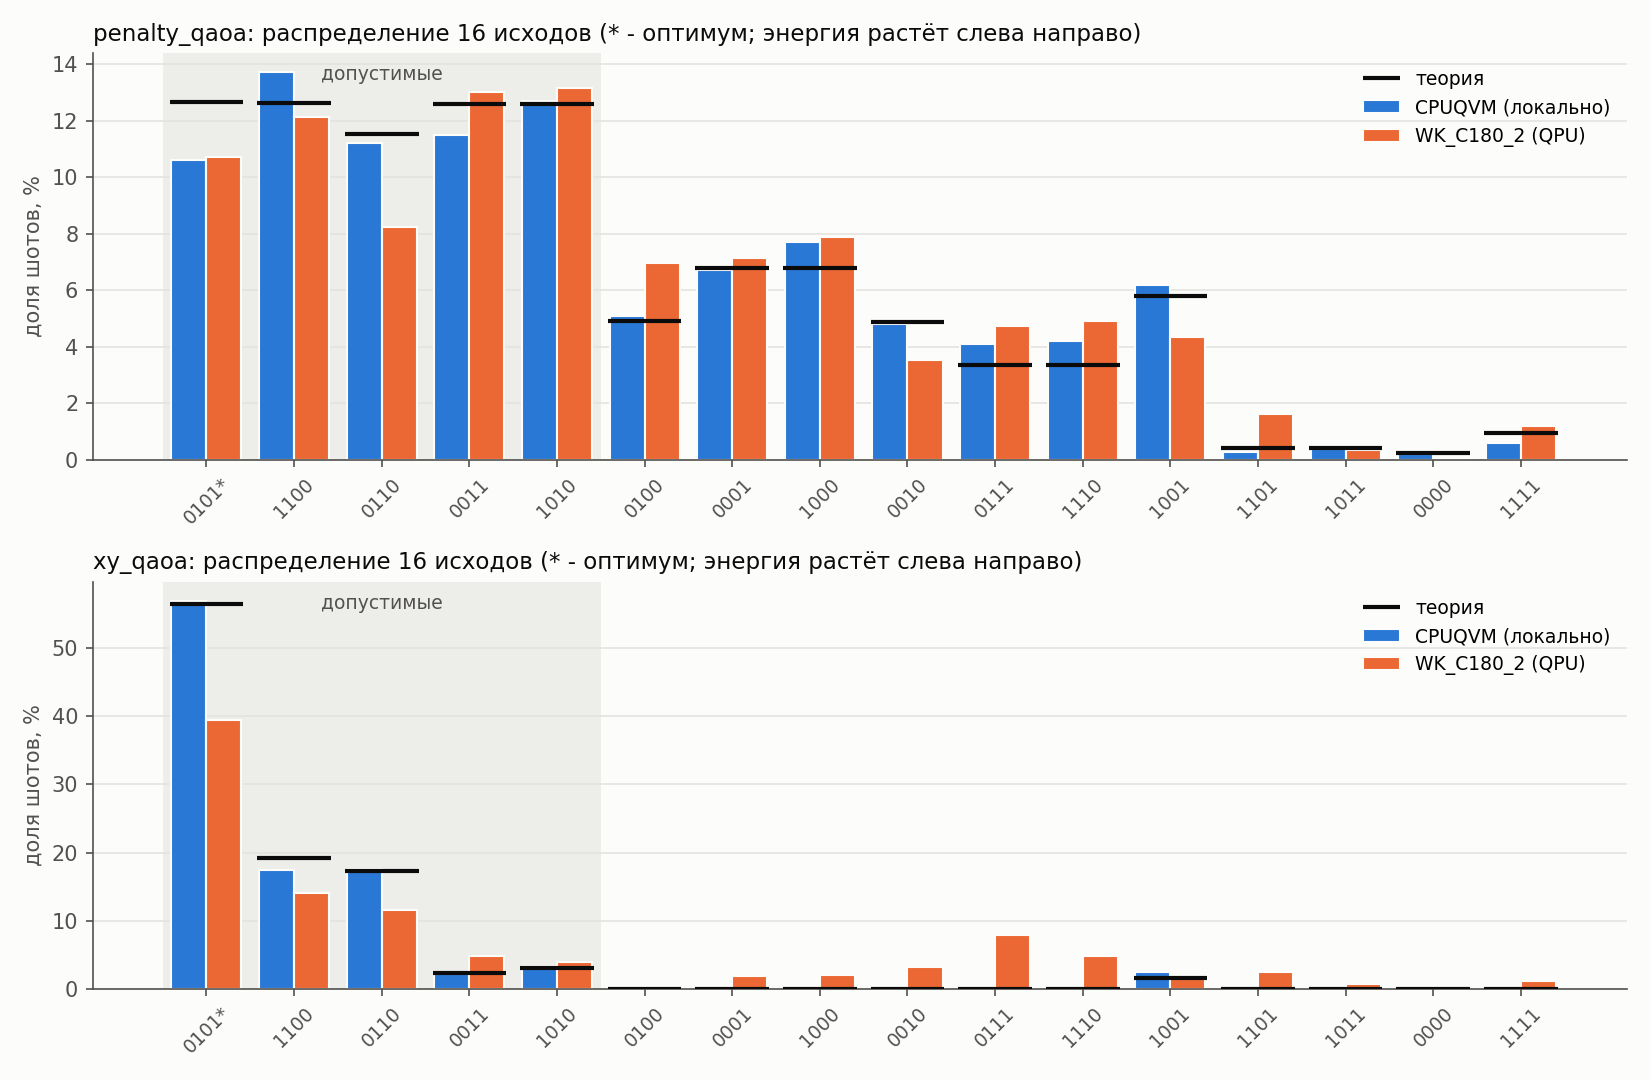

In [10]:
# ===== src/step5_analysis.py (код файла проекта 1:1) =====
# -*- coding: utf-8 -*-
"""
Шаг 5. Анализ результатов: теория vs симуляторы vs квантовый компьютер.

Что делает: собирает всё, что есть - теорию (шаг 2), CPUQVM (шаг 3), облачный симулятор и QPU (шаг 4),
переводит ответы бэкендов в общий порядок битов, считает метрики и печатает выводы.
Шаги 3 и 4 необязательны: анализ строится по тем источникам, которые уже готовы.

Метрики (для каждой схемы и каждого источника):
  P(opt)       - доля шотов с оптимальным ответом 0101;
  P(feas)      - доля допустимых ответов (ровно 2 линии и без КЗ);
  P(opt|feas)  - доля оптимума среди допустимых: умеет ли схема выбирать лучший из допустимых
                 (случайный выбор из 5 допустимых даёт 20%);
  <H>          - средняя энергия ответа (меньше - лучше);
  ранг         - место оптимума среди допустимых по частоте (1 - самый частый);
  TVD          - расстояние до теории: 0 - совпадение, 1 - ничего общего.

Вход:  results/step1..step4 (что есть)
Выход: results/step5_report.md, results/step5_plot.png
Запуск: python src/step5_analysis.py      (в Jupyter: %run src/step5_analysis.py)
"""
import importlib
import os
import sys
import time
from datetime import datetime

import numpy as np

# Общие функции: если код common.py вставлен в ячейку ноутбука выше - берём их оттуда,
# иначе импортируем файл src/common.py (запуск через python или %run).
if "load_circuits" in globals() and "Problem" in globals():
    import types
    C = types.SimpleNamespace(**globals())
else:
    sys.path.insert(0, os.path.dirname(os.path.abspath(
        globals().get("__file__", os.path.join(os.getcwd(), "src", "_")))))
    try:
        import common as C  # noqa: E402
    except ImportError:
        raise SystemExit("Нет общих функций: сначала выполните ячейку с кодом src/common.py "
                         "(или положите файл src/common.py рядом).")
    C = importlib.reload(C)   # Jupyter кеширует модули: перечитываем, если common.py обновили

MAIN = ["penalty_qaoa", "xy_qaoa", "legacy_qaoa"]
COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]          # проверенная палитра: синий, оранжевый, бирюзовый
INK, INK2, SURFACE, GRID = "#0b0b0b", "#52514e", "#fcfcfb", "#e4e3df"


def collect_sources(P, exact):
    """[(название, анализ)] для всех готовых источников с измерениями."""
    out = []
    if os.path.exists(C.STEP3_PATH):
        s3 = C.load_json(C.STEP3_PATH, "шаг 3")
        out.append(("CPUQVM (локально)", C.analyse_raw(P, exact, s3["raw"])))
    if os.path.exists(C.STEP4_PATH):
        s4 = C.load_json(C.STEP4_PATH, "шаг 4")
        for t in s4["tiers"]:
            if t["status"] == "done":
                label = f"{t['backend']} ({'QPU' if t.get('type') == 'qpu' else 'облачный симулятор'})"
                out.append((label, C.analyse_raw(P, exact, t["raw"])))
            else:
                print(f"   {t['backend']}: {'ещё выполняется' if t['status'] == 'pending' else 'ошибка'} - "
                      f"в анализ не входит")
    return out


def rows_for(P, exact, sources, name):
    uni = np.full(2 ** P.n, 1 / 2 ** P.n)
    rows = [("случайное угадывание", C.metrics(P, uni, exact[name])),
            ("теория (без шума)", C.metrics(P, exact[name], exact[name]))]
    rows += [(label, a["metrics"][name]) for label, a in sources if name in a["metrics"]]
    return rows


def fmt_row(label, m):
    pof = m["p_opt_given_feasible"]
    return (f"| {label} | {m['p_opt']:.1%} | {m['p_feasible']:.1%} | "
            f"{(f'{pof:.1%}' if pof is not None else '-')} | {m['exp_H']:.2f} | {m['mode']} | "
            f"{m['opt_rank_among_feasible']} | {m['tvd']:.3f} |")


def conclusions(P, exact, sources):
    opt = P.opt_strings()[0]
    k_opt = int(opt, 2)
    lines = []
    for name in [c for c in MAIN if c in exact]:
        series = [("теория", exact[name])] + [(lbl, a["probs"][name]) for lbl, a in sources if name in a["probs"]]
        for label, p in series:
            m = C.metrics(P, p)
            margin = m["p_opt"] - max(p[k] for k in range(2 ** P.n) if k != k_opt)
            if m["mode"] == opt:
                where = (f"самый частый, но отрыв всего {100 * margin:.1f} п.п. - фактически вровень с другими"
                         if margin < 0.01 else f"самый частый исход (отрыв {100 * margin:.1f} п.п.)")
            else:
                where = (f"не самый частый (чаще всего {m['mode']}; среди допустимых оптимум на месте "
                         f"{m['opt_rank_among_feasible']})")
            pof = m["p_opt_given_feasible"]
            select = (f"среди допустимых выделяется: {pof:.0%} против случайных 20%" if pof >= 0.3 else
                      f"среди допустимых не выделяется: {pof:.0%}, как случайный выбор (20%)")
            lines.append(f"- **{name}, {label}:** оптимум {opt} - {where}; P(opt) = {m['p_opt']:.1%} "
                         f"({m['p_opt'] * 2 ** P.n:.1f}x от случайного); {select}.")
    for label, a in sources:
        side = "правый" if a["order"] == "q0_right" else "левый"
        lines.append(f"- Порядок битов, {label}: кубит 0 - {side} символ ключа "
                     f"(калибровка {a['calib_top']!r}, {a['calib_share']:.0%}).")
    return lines


def plot(P, exact, sources, path):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    names = [c for c in ("penalty_qaoa", "xy_qaoa") if c in exact]
    order = sorted(range(2 ** P.n), key=lambda k: P.E[k])
    labels = [C.xstr(k, P.n) + ("*" if P.optimal[k] else "") for k in order]
    nfeas = int(P.feasible.sum())
    fig, axes = plt.subplots(len(names), 1, figsize=(11, 3.6 * len(names)), facecolor=SURFACE, squeeze=False)
    for ax, name in zip(axes[:, 0], names):
        ax.set_facecolor(SURFACE)
        ax.axvspan(-0.5, nfeas - 0.5, color=GRID, alpha=0.6, lw=0, zorder=0)
        ax.text(nfeas / 2 - 0.5, 0.97, "допустимые", transform=ax.get_xaxis_transform(), ha="center",
                va="top", color=INK2, fontsize=9)
        m = len(sources)
        width = 0.8 / max(m, 1)
        xs = np.arange(len(order))
        for i, (label, a) in enumerate(sources[:3]):
            if name not in a["probs"]:
                continue
            ys = [100 * a["probs"][name][k] for k in order]
            ax.bar(xs - 0.4 + width * (i + 0.5), ys, width, color=COLORS[i], label=label,
                   edgecolor=SURFACE, linewidth=1.0, zorder=2)
        th = [100 * exact[name][k] for k in order]
        ax.hlines(th, xs - 0.42, xs + 0.42, colors=INK, linewidth=2, label="теория", zorder=3)
        ax.set_xticks(xs)
        ax.set_xticklabels(labels, rotation=45, fontsize=9, color=INK2)
        ax.set_ylabel("доля шотов, %", color=INK2)
        ax.set_title(f"{name}: распределение 16 исходов (* - оптимум; энергия растёт слева направо)",
                     loc="left", fontsize=11, color=INK)
        ax.grid(axis="y", color=GRID, linewidth=0.8, zorder=1)
        ax.tick_params(colors=INK2)
        for s in ("top", "right"):
            ax.spines[s].set_visible(False)
        for s in ("left", "bottom"):
            ax.spines[s].set_color(INK2)
        ax.legend(loc="upper right", frameon=False, fontsize=9)
    fig.tight_layout()
    fig.savefig(path, dpi=150, facecolor=SURFACE)
    plt.close(fig)


def main():
    t0 = time.time()
    s2, P, gates, exact = C.load_circuits()
    print("=" * 72)
    print("ШАГ 5. Анализ: теория, симуляторы, квантовый компьютер")
    print("=" * 72)
    sources = collect_sources(P, exact)
    if not sources:
        print("   измерений пока нет - сравниваю только с теорией (выполните шаг 3 и/или шаг 4)")

    md = [f"# Шаг 5. Анализ результатов", "",
          f"Создан: {datetime.now().isoformat(timespec='seconds')}. Оптимум задачи: {P.opt_strings()} "
          f"(H = {P.E_opt:.3f}). Источники: теория" + "".join(f", {lbl}" for lbl, _ in sources) + ".", ""]
    header = "| источник | P(opt) | P(feas) | P(opt\\|feas) | ⟨H⟩ | самый частый | ранг оптимума | TVD |"
    for name in [c for c in MAIN if c in exact]:
        md += [f"## {name} - {s2['circuits'][name]['title']}", "", header, "|---|---|---|---|---|---|---|---|"]
        md += [fmt_row(label, m) for label, m in rows_for(P, exact, sources, name)]
        md.append("")
        print(f"\n{name} ({s2['circuits'][name]['title']}):")
        print(f"   {'источник':<36}{'P(opt)':>8}{'P(feas)':>9}{'P(opt|f)':>10}{'<H>':>8}  {'частый':<7}{'ранг':>5}{'TVD':>7}")
        for label, m in rows_for(P, exact, sources, name):
            pof = m["p_opt_given_feasible"]
            print(f"   {label[:35]:<36}{m['p_opt']:8.1%}{m['p_feasible']:9.1%}"
                  f"{(f'{pof:.1%}' if pof is not None else '-'):>10}{m['exp_H']:8.2f}  {m['mode']:<7}"
                  f"{str(m['opt_rank_among_feasible']):>5}{m['tvd']:7.3f}")

    order = sorted(range(2 ** P.n), key=lambda k: P.E[k])
    for name in [c for c in ("penalty_qaoa", "xy_qaoa") if c in exact]:
        md += [f"### {name}: вероятности всех 16 исходов, %", "",
               "| x | H | допустимо | теория | " + " | ".join(lbl for lbl, _ in sources) + " |",
               "|---|---|---|---|" + "---|" * len(sources)]
        for k in order:
            cells = [f"{100 * a['probs'][name][k]:.1f}" if name in a["probs"] else "-" for _, a in sources]
            md.append(f"| {C.xstr(k, P.n)}{' *' if P.optimal[k] else ''} | {P.E[k]:.1f} | "
                      f"{'да' if P.feasible[k] else '-'} | {100 * exact[name][k]:.1f} | " + " | ".join(cells) + " |")
        md.append("")

    concl = conclusions(P, exact, sources)
    md += ["## Выводы", ""] + concl + ["", f"![График](step5_plot.png)", ""]
    print("\nВыводы:")
    for line in concl:
        print("   " + line.replace("**", ""))

    plot(P, exact, sources, C.STEP5_PLOT)
    os.makedirs(C.RESULTS_DIR, exist_ok=True)
    with open(C.STEP5_REPORT, "w", encoding="utf-8") as f:
        f.write("\n".join(md))
    print(f"\nСохранено: {C.rel(C.STEP5_REPORT)}, {C.rel(C.STEP5_PLOT)}   ({time.time() - t0:.1f} с)")
    try:                                     # в Jupyter сразу показать график под ячейкой
        from IPython import get_ipython
        if get_ipython() is not None:
            from IPython.display import Image, display
            display(Image(filename=C.STEP5_PLOT))
    except Exception:  # noqa: BLE001
        pass


if __name__ == "__main__":
    main()